## Make datasets and plot them


In [185]:
from sklearn.datasets import make_moons

In [186]:
n_samples = 2000
manualSeed=42

X,y = make_moons(n_samples=n_samples,
          noise=0.15,
          random_state=manualSeed)

X.shape, y.shape

((2000, 2), (2000,))

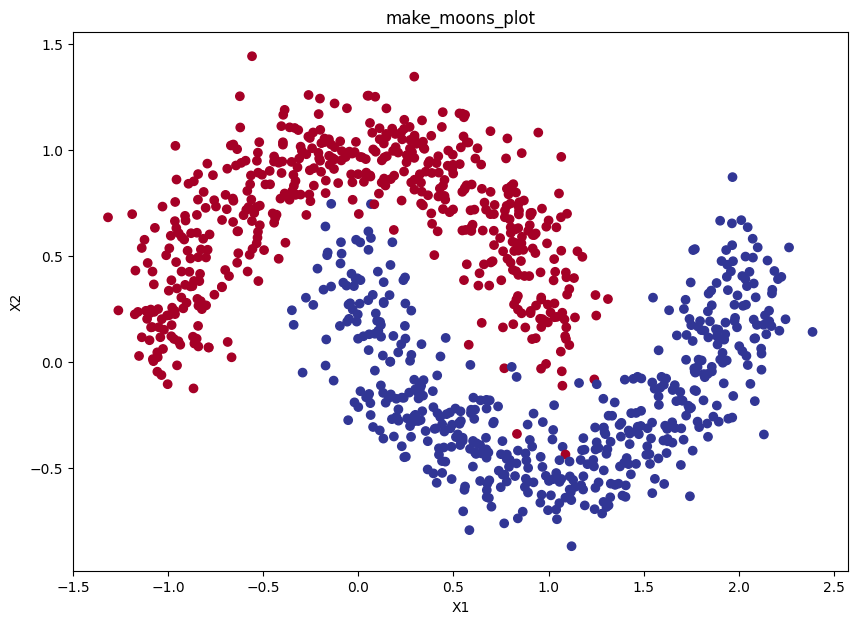

In [188]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,7))
plt.scatter(X[:1000,0],
            X[:1000,1],
            c=y[:1000],
            cmap=plt.cm.RdYlBu)
plt.title("make_moons_plot")
plt.xlabel("X1")
plt.ylabel("X2")

plt.show()

In [189]:
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
X,y=torch.from_numpy(X).to(device),torch.from_numpy(y).to(device)

X_train,X_test,y_train,y_test = train_test_split(X,
                                                 y,
                                                 test_size=0.5,
                                                 random_state=manualSeed)

## Make the model class and a model instance

In [190]:
import torch
from torch import nn

In [191]:
class MoonModel0(nn.Module):
  def __init__(self, input_features, output_features, hidden_layer_1, hidden_layer_2):
    super().__init__()
    self.perceptron = nn.Sequential(
        nn.Linear(in_features=input_features, out_features=hidden_layer_1),
        nn.ReLU(),
        nn.Linear(in_features=hidden_layer_1, out_features=hidden_layer_1),
        nn.ReLU(),
        nn.Linear(in_features=hidden_layer_1, out_features=hidden_layer_2),
        nn.ReLU(),
        nn.Linear(in_features=hidden_layer_2, out_features=hidden_layer_2),
        nn.ReLU(),
        nn.Linear(in_features=hidden_layer_2, out_features=output_features)
    )

  def forward(self,x:torch.Tensor) -> torch.Tensor:
    return self.perceptron(x)

In [192]:
model_0 =  MoonModel0(2,1,10,10)
model_0

MoonModel0(
  (perceptron): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=10, bias=True)
    (3): ReLU()
    (4): Linear(in_features=10, out_features=10, bias=True)
    (5): ReLU()
    (6): Linear(in_features=10, out_features=10, bias=True)
    (7): ReLU()
    (8): Linear(in_features=10, out_features=1, bias=True)
  )
)

### Setup Loss Fn, Accuracy Fn and an Optimizer

In [193]:
#Setup the Loss Fn, Accuracy Fn and Optimizer
learning_rate = 0.03

loss_fn = nn.BCEWithLogitsLoss()
optimizer  = torch.optim.Adam(params=model_0.parameters(), lr=learning_rate)

def accuracy(input, target):
  acc = torch.eq(input, target).sum().item()
  return (acc/len(target)) * 100

In [194]:
epoch_count = []
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []

## Training and Evaluation Loop

In [196]:
epochs = 1000
torch.manual_seed = manualSeed

for epoch in range(1,epochs+1):
  #Training Loops
  model_0.train()

  # Forward pass
  y_logits = model_0(X_train.type(torch.float)).squeeze(dim=1)
  y_predProbs = torch.sigmoid(y_logits)
  y_labels = torch.round(y_predProbs)

  #Gradient
  optimizer.zero_grad()

  #Loss and Accuracy Calculation
  loss = loss_fn(y_logits, y_train.type(torch.float))
  acc =  accuracy(y_labels, y_train)

  #Backpropagation
  loss.backward()

  #Gradient Descent
  optimizer.step()

  #Evaluation Loop
  model_0.eval()
  with torch.inference_mode():

    #Test forward
    y_test_logits = model_0(X_test.type(torch.float)).squeeze()
    y_test_labels = torch.round(torch.sigmoid(y_test_logits))

    #Test Loss and Accuracy Calculation
    test_loss = loss_fn(y_test_logits, y_test.type(torch.float))
    test_acc =  accuracy(y_test_labels, y_test)


  if epoch%20 == 0:
    print(f"Epoch:{epoch} | Loss:{loss:.5f} | Accuracy:{acc:.2f} | Loss:{test_loss:.5f} | Accuracy:{test_acc:.2f}")
    epoch_count.append(epoch)
    train_losses.append(loss)
    train_accuracies.append(acc)
    test_losses.append(test_loss)
    test_accuracies.append(test_acc)

Epoch:20 | Loss:0.25206 | Accuracy:90.40 | Loss:0.22173 | Accuracy:90.70
Epoch:40 | Loss:0.02468 | Accuracy:99.10 | Loss:0.02585 | Accuracy:98.90
Epoch:60 | Loss:0.02460 | Accuracy:99.00 | Loss:0.02682 | Accuracy:99.10
Epoch:80 | Loss:0.02266 | Accuracy:98.90 | Loss:0.02425 | Accuracy:99.10
Epoch:100 | Loss:0.02201 | Accuracy:99.10 | Loss:0.02484 | Accuracy:99.20
Epoch:120 | Loss:0.02215 | Accuracy:99.20 | Loss:0.02543 | Accuracy:99.20
Epoch:140 | Loss:0.02211 | Accuracy:99.30 | Loss:0.02575 | Accuracy:99.30
Epoch:160 | Loss:0.02108 | Accuracy:99.10 | Loss:0.02605 | Accuracy:99.20
Epoch:180 | Loss:0.02080 | Accuracy:99.00 | Loss:0.02643 | Accuracy:99.30
Epoch:200 | Loss:0.02106 | Accuracy:98.90 | Loss:0.02823 | Accuracy:99.20
Epoch:220 | Loss:0.02011 | Accuracy:99.20 | Loss:0.02725 | Accuracy:99.30
Epoch:240 | Loss:0.01940 | Accuracy:99.20 | Loss:0.02969 | Accuracy:99.20
Epoch:260 | Loss:0.01960 | Accuracy:99.30 | Loss:0.02669 | Accuracy:99.30
Epoch:280 | Loss:0.01853 | Accuracy:99.30 

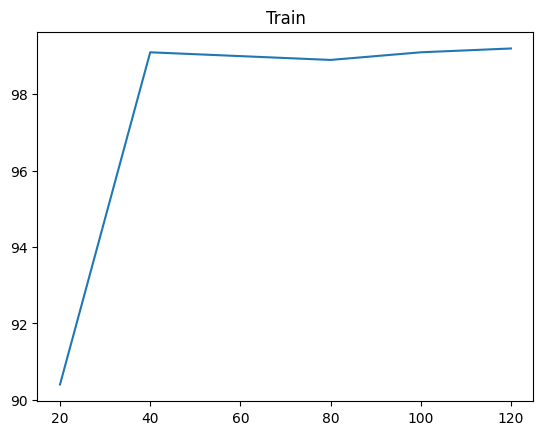

In [199]:
plt.title("Train")
plt.plot(epoch_count[:6], train_accuracies[:6])
plt.show()

In [160]:
import os, requests

if not os.path.exists("helper_functions.py"):
  r = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  open("helper_functions.py", "wb").write(r.content)

from helper_functions import plot_decision_boundary

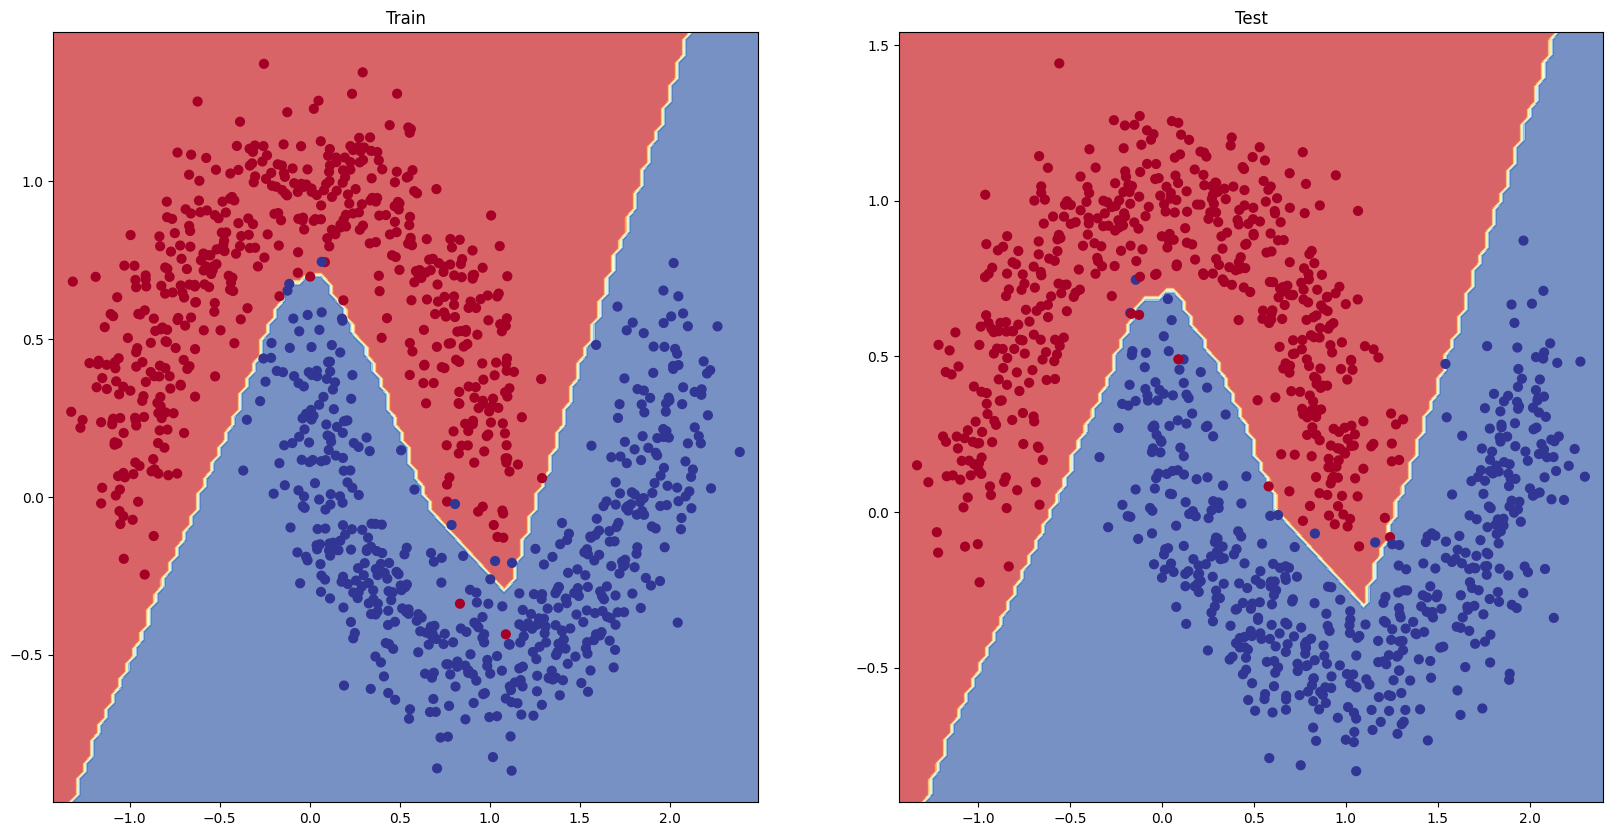

In [169]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(20,10))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)